## Cargar los datos ##

In [126]:
import numpy as np
import pandas as pd

In [127]:
df = pd.read_csv('data/GenreAll.csv', skipinitialspace=True)

# eliminar filas que no tienen género
df = df.dropna(subset=['genre']) 

#feature que queremos predecir
y = df['genre'] 

#features para el entrenamiento
X = df.drop(columns=["genre"]).copy()

# Convertir columnas binarias de texto en 0 y 1
text_columns = X.select_dtypes(include=['str', 'object', 'string']).columns

for col in text_columns:
    values = X[col].dropna().unique()

    if len(values) == 2:
        X[col] = X[col].map({
            values[0]: 0,
            values[1]: 1})
            
#asegurar que solo hay valores numéricos
X = X.select_dtypes(include=np.number)

print("Número de canciones:", len(df))
print("Número de features:", X.shape[1])
print("\nCanciones por género:")
print(y.value_counts())

df.head()

Número de canciones: 993
Número de features: 240

Canciones por género:
genre
blu    100
cou    100
dis    100
hip    100
jaz    100
met    100
pop    100
reg    100
roc    100
cla     93
Name: count, dtype: int64


,highlevel_danceability_value,highlevel_equalization_profile_value,highlevel_excitement_value,highlevel_intensity_value,highlevel_speech_music_value,highlevel_voice_instrumental_value,loudness_dynamic_complexity_dvar,loudness_dynamic_complexity_mean,loudness_dynamic_complexity_var,loudness_larm_dvar,...,tonal_chords_strength_dvar,tonal_chords_strength_mean,tonal_chords_strength_var,tonal_dissonance_dvar,tonal_dissonance_mean,tonal_dissonance_var,tonal_key_mode_value,tonal_key_strength_value,tonal_tuning_equal_tempered_deviation_value,genre
0,0.477744,0.372766,0.029087,0.093526,speech,instrumental,-0.366526,0.832351,-0.398487,0.262413,...,0.175405,0.101673,0.989475,0.167484,-0.091051,0.085449,major,0.162259,2.423830,blu
1,0.271161,0.372766,-1.283803,-0.615420,speech,voice,0.275184,1.901008,-0.287263,0.078360,...,-0.157583,-0.652126,-0.992276,0.606661,-0.468630,0.416914,major,0.230571,-0.207952,blu
2,0.089011,0.372766,0.029087,1.511419,music,instrumental,-0.177390,0.046932,0.035041,-0.157974,...,-0.001059,-0.220255,0.978014,-0.236338,0.470580,-0.205887,major,1.024735,-0.211034,blu
3,0.243503,0.372766,0.029087,-0.615420,music,instrumental,-0.319420,-0.953075,0.239607,-0.659566,...,0.214463,0.853728,1.327351,-0.542341,0.642223,-0.791110,major,0.079033,0.148357,blu
4,0.594883,-1.940715,-1.283803,0.093526,speech,instrumental,-0.224956,1.154507,-0.420087,0.281666,...,-0.140930,-0.080519,-1.163700,0.094741,-0.164770,-0.277919,major,-0.337966,-0.277459,blu


## Definición de los modelos ##

Un pipeline es una cadena de pasos que se ejecutan en orden. Por ejemplo, antes de entrenar un modelo, podemos necesitar rellenar datos que faltan y normalizar las características.

`Pipeline` permite crear un pipeline combinando varios pasos

`SimpleImputer` sirve para rellenar los valores que faltan en los datos, por ejemplo, cuando una característica musical contiene NaN. se puede usar `StandardScaler` para rellenar esos datos vacíos

In [128]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

#modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

In [129]:
# Número de características que se van a probar
feature_options = [k for k in [130, 150, 200] if k <= X.shape[1]] + ["all"]

models = {
    "Logistic Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold(threshold=0.0)),
            ("scaler", StandardScaler()),
            ("selector", SelectKBest(score_func=f_classif)),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        {
            "selector__k": [130, 150],
            "model__C": [0.1, 0.3, 1]
        }
    ),

    "k-NN": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold(threshold=0.0)),
            ("scaler", StandardScaler()),
            ("selector", SelectKBest(score_func=f_classif)),
            ("model", KNeighborsClassifier())
        ]),
        {
            "selector__k": [90, 130],
            "model__n_neighbors": [3, 5],
            "model__weights": ["distance"]
        }
    ),

    "Decision Tree": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold(threshold=0.0)),
            ("selector", SelectKBest(score_func=f_classif)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeClassifier(random_state=42))
        ]),
        {
            "selector__k": [200, "all"],
            "model__max_depth": [10, 15],
            "model__min_samples_leaf": [5, 10]
        }
        	
    ),

    "Artificial Neural Network": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold(threshold=0.0)),
            ("scaler", StandardScaler()),
            ("selector", SelectKBest(score_func=f_classif)),
            ("model", MLPClassifier(
                solver="adam",
                learning_rate_init=0.001,
                max_iter=700,
                random_state=42,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                tol=1e-3
            ))
        ]),
        {
            "selector__k": [130, 150],
            "model__hidden_layer_sizes": [(50,), (100,)],
            "model__alpha": [0.01, 0.1]
        }
    )
}


## Definir la validación cruzada
 
Mismo esquema de 10 folds para comparar todos los algoritmos

In [130]:
from sklearn.model_selection import StratifiedKFold

In [131]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42)

## Entrenar y evaluar los modelos

Esta es la celda principal. `GridSearchCV` probará todas las configuraciones usando validación cruzada de 10 folds y seleccionará la que obtenga la mejor accuracy media para cada algoritmo

In [132]:
from sklearn.model_selection import GridSearchCV

In [133]:

results = []
best_models = {}

for name, (pipeline, params) in models.items():

    print("\nEvaluando:", name)

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring="accuracy",
        cv=cv,
        return_train_score=True,
        n_jobs=-1)

    search.fit(X, y)

    best_models[name] = search

    # Guardar los resultados de todas las configuraciones
    for i in range(len(search.cv_results_["params"])):
        results.append({
            "Algorithm": name,
            "Parameters": search.cv_results_["params"][i],
            "Train accuracy": search.cv_results_["mean_train_score"][i],
            "CV accuracy": search.cv_results_["mean_test_score"][i]})

    # Seleccionar la configuración con mayor accuracy
    # entre las que tienen overfitting < 0.15
    cv_results = pd.DataFrame(search.cv_results_)


for name, search in best_models.items():

    best_pipeline = search.best_estimator_
    feature_names = X.columns.to_numpy()

    variance_selector = best_pipeline.named_steps["variance"]
    feature_names = feature_names[variance_selector.get_support()]

    selector = best_pipeline.named_steps["selector"]
    selected_features = feature_names[selector.get_support()].tolist()

    print(f"\nAlgorithm: {name}")
    print(f"Best parameters: {search.best_params_}")
    print(f"CV accuracy: {search.best_score_:.4f}")
    print(f"Selected features ({len(selected_features)}):")


results_df = pd.DataFrame(results)

results_df["Overfitting gap"] = (
    results_df["Train accuracy"] -
    results_df["CV accuracy"]
)

results_df = results_df.sort_values(
    ["CV accuracy", "Overfitting gap"],
    ascending=[False, True]
).reset_index(drop=True)

print(f"Total configs evaluated: {len(results_df)}")

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.width", None
): display(results_df)




Evaluando: Logistic Regression

Evaluando: k-NN

Evaluando: Decision Tree

Evaluando: Artificial Neural Network

Algorithm: Logistic Regression
Best parameters: {'model__C': 0.3, 'selector__k': 130}
CV accuracy: 0.8559
Selected features (130):

Algorithm: k-NN
Best parameters: {'model__n_neighbors': 5, 'model__weights': 'distance', 'selector__k': 130}
CV accuracy: 0.7713
Selected features (130):

Algorithm: Decision Tree
Best parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 5, 'selector__k': 200}
CV accuracy: 0.6535
Selected features (200):

Algorithm: Artificial Neural Network
Best parameters: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (100,), 'selector__k': 150}
CV accuracy: 0.7965
Selected features (150):
Total configs evaluated: 26


,Algorithm,Parameters,Train accuracy,CV accuracy,Overfitting gap
0,Logistic Regression,"{'model__C': 0.3, 'selector__k': 130}",0.981873,0.855929,0.125944
1,Logistic Regression,"{'model__C': 0.3, 'selector__k': 150}",0.985454,0.851899,0.133555
2,Logistic Regression,"{'model__C': 1, 'selector__k': 130}",0.993733,0.850919,0.142814
3,Logistic Regression,"{'model__C': 0.1, 'selector__k': 150}",0.961955,0.848879,0.113076
4,Logistic Regression,"{'model__C': 0.1, 'selector__k': 130}",0.953675,0.847899,0.105776
5,Logistic Regression,"{'model__C': 1, 'selector__k': 150}",0.996531,0.843848,0.152683
6,Artificial Neural Network,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (100,), 'selector__k': 150}",0.901090,0.796465,0.104625
7,Artificial Neural Network,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (100,), 'selector__k': 150}",0.889113,0.792495,0.096618
8,Artificial Neural Network,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (50,), 'selector__k': 130}",0.856886,0.779414,0.077472
9,Artificial Neural Network,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (100,), 'selector__k': 130}",0.852740,0.779384,0.073356


Select the configuration you want to plot a as a confusion matrix (row number).

Selected algorithm: Logistic Regression
Parameters: {'model__C': 0.3, 'selector__k': 130}
CV accuracy: 0.8559
Overfitting gap: 0.1259


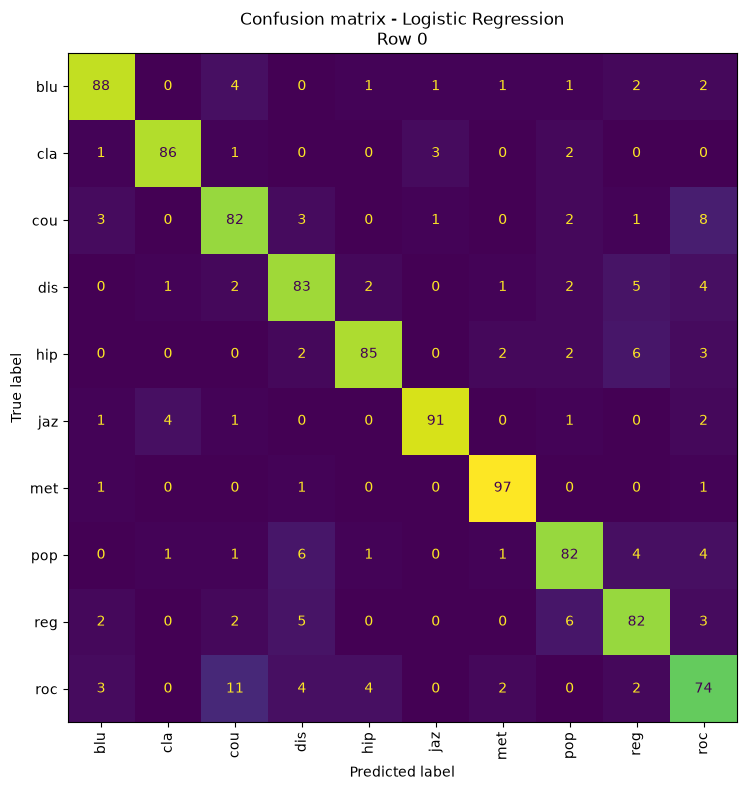

In [134]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Seleccionar una fila de la tabla ordenada
num_rows = len(results_df)

print("Select the configuration you want to plot a as a confusion matrix (row number).")
row = int(input(f"Introduce a number between 0 y {num_rows - 1}: "))

if row < 0 or row > num_rows:
    raise ValueError(f"Row number must be between 0 and {num_rows}.")

# Obtener la configuración elegida
selected_row = results_df.iloc[row]
name = selected_row["Algorithm"]
params = selected_row["Parameters"]

print(f"\nSelected algorithm: {name}")
print(f"Parameters: {params}")
print(f"CV accuracy: {selected_row['CV accuracy']:.4f}")
print(f"Overfitting gap: {selected_row['Overfitting gap']:.4f}")

# Reconstruir el pipeline con los parámetros seleccionados
pipeline, _ = models[name]
selected_model = clone(pipeline)
selected_model.set_params(**params)

# Obtener predicciones out-of-fold mediante validación cruzada.
# Cada muestra se predice con un modelo que no la ha utilizado para entrenar.
y_pred = cross_val_predict(
    selected_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

# Matriz de confusión
classes = np.unique(y)

cm = confusion_matrix(y, y_pred, labels=classes)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    values_format="d",
    colorbar=False
)

ax.set_title(f"Confusion matrix - {name}\nRow {row}")
plt.tight_layout()
plt.show()
